# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Sebastian Arreguin Villanueva  
**Grupo:** 512  **Fecha:** 26 de Octubre 2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ruta = Path("../data/raw/nyc_taxi_examen.csv")
if not ruta.is_file():
    ruta = Path(r"C:\Users\sebar\Documents\nyc_taxi_examen.csv\nyc_taxi_examen.csv")

df = pd.read_csv(ruta, index_col=0)

print(f"Archivo cargado: {ruta.name}")
print("Primeras cinco filas:")
display(df.head())
print(f"\nDimensiones: {df.shape}")
print("\nColumnas:")
print(df.columns.tolist())
print("\nTipos de datos:")
print(df.dtypes)
print("\nResumen estadístico de columnas numéricas:")
display(df.describe())
print("\nValores de payment_type:")
print(df["payment_type"].value_counts(dropna=False))

Archivo cargado: nyc_taxi_examen.csv
Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000



Dimensiones: (2427612, 20)

Columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type                 str
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_co

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03



Valores de payment_type:
payment_type
Credit card    2051983
Cash            329533
Dispute          23558
NaN              12125
No charge        10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()
dimensiones_antes = df_limpio.shape
nulos_antes = df_limpio.isna().sum()
duplicados_antes = df_limpio.duplicated().sum()

print(f"Dimensiones antes de limpiar: {dimensiones_antes}")
print("Valores nulos por columna antes de limpiar:")
display(nulos_antes.to_frame("valores_nulos"))
print(f"Registros duplicados antes de limpiar: {duplicados_antes}")

df_limpio = df_limpio.drop_duplicates().dropna()
df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0)
    & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0)
    & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
].copy()

print(f"Dimensiones después de limpiar: {df_limpio.shape}")
print(f"Registros conservados: {len(df_limpio):,}")

Dimensiones antes de limpiar: (2427612, 20)
Valores nulos por columna antes de limpiar:


,valores_nulos
VendorID,0
tpep_pickup_datetime,12126
tpep_dropoff_datetime,12127
passenger_count,12123
trip_distance,12142
RatecodeID,12138
PULocationID,12125
DOLocationID,12137
payment_type,12125
fare_amount,12124


Registros duplicados antes de limpiar: 11961


Dimensiones después de limpiar: (2096600, 20)
Registros conservados: 2,096,600


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [3]:
df_cash = df_limpio.loc[df_limpio["payment_type"] == "Cash"].copy()
X = df_cash[["trip_distance", "trip_duration"]].copy()

print(f"Viajes pagados en efectivo: {len(df_cash):,}")
print("Estadísticas descriptivas de las variables de agrupamiento:")
display(X.describe())

Viajes pagados en efectivo: 282,085


Estadísticas descriptivas de las variables de agrupamiento:


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
X_log = np.log1p(X)
scaler = StandardScaler()
X_escalado = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=X.columns,
    index=X.index,
)

print("Variables después de aplicar log1p:")
display(X_log.describe())
print("Variables estandarizadas:")
display(X_escalado.describe())

Variables después de aplicar log1p:


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,1.225454,2.607608
std,0.763298,0.744450
min,0.009950,0.032790
25%,0.652325,2.128232
50%,0.993252,2.596498
75%,1.680828,3.085725
max,7.430997,9.032967


Variables estandarizadas:


,trip_distance,trip_duration
count,2.820850e+05,2.820850e+05
mean,2.095721e-16,-2.180356e-16
std,1.000002e+00,1.000002e+00
min,-1.592439e+00,-3.458691e+00
25%,-7.508596e-01,-6.439344e-01
50%,-3.042097e-01,-1.492393e-02
75%,5.965880e-01,6.422437e-01
max,8.129920e+00,8.631030e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,227681.23,0.5320
1,3,137511.96,0.4478
2,4,100620.19,0.4191
3,5,79205.37,0.3894
4,6,66980.31,0.3737


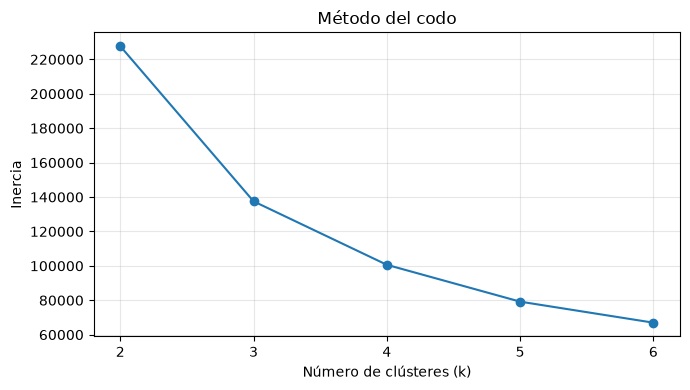

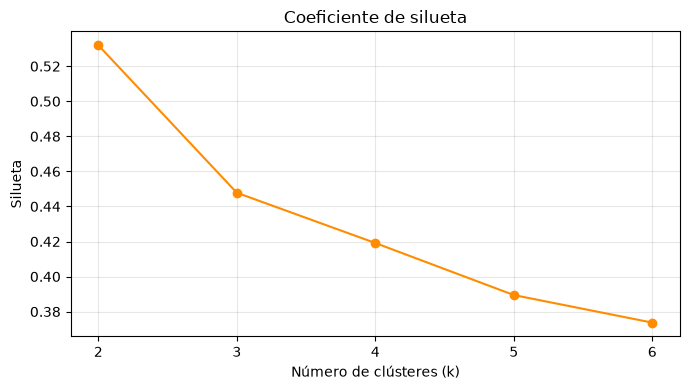

In [5]:
resultados_k = []
modelos = {}
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    silueta = silhouette_score(
        X_escalado,
        etiquetas,
        sample_size=5000,
        random_state=42,
    )
    resultados_k.append({"k": k, "Inercia": modelo.inertia_, "Silueta": silueta})
    modelos[k] = modelo

tabla_k = pd.DataFrame(resultados_k)
display(tabla_k.round({"Inercia": 2, "Silueta": 4}))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tabla_k["k"], tabla_k["Inercia"], marker="o")
ax.set(title="Método del codo", xlabel="Número de clústeres (k)", ylabel="Inercia")
ax.set_xticks(tabla_k["k"])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tabla_k["k"], tabla_k["Silueta"], marker="o", color="darkorange")
ax.set(title="Coeficiente de silueta", xlabel="Número de clústeres (k)", ylabel="Silueta")
ax.set_xticks(tabla_k["k"])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

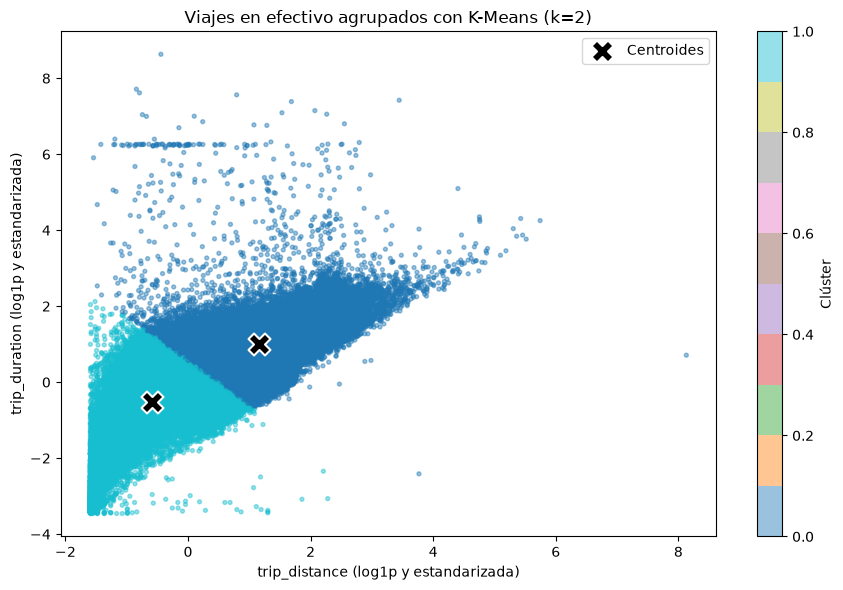

In [6]:
k_elegido = int(tabla_k.loc[tabla_k["Silueta"].idxmax(), "k"])
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
etiquetas_finales = modelo_final.fit_predict(X_escalado)

fig, ax = plt.subplots(figsize=(9, 6))
puntos = ax.scatter(
    X_escalado["trip_distance"],
    X_escalado["trip_duration"],
    c=etiquetas_finales,
    cmap="tab10",
    s=8,
    alpha=0.45,
)
ax.scatter(
    modelo_final.cluster_centers_[:, 0],
    modelo_final.cluster_centers_[:, 1],
    marker="X",
    s=250,
    c="black",
    edgecolors="white",
    linewidths=1.5,
    label="Centroides",
)
ax.set_title(f"Viajes en efectivo agrupados con K-Means (k={k_elegido})")
ax.set_xlabel("trip_distance (log1p y estandarizada)")
ax.set_ylabel("trip_duration (log1p y estandarizada)")
ax.legend()
fig.colorbar(puntos, ax=ax, label="Clúster")
plt.tight_layout()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas_finales

estadisticos_cluster = (
    df_resultado.groupby("cluster")
    .agg(
        cantidad_viajes=("trip_distance", "size"),
        distancia_media_millas=("trip_distance", "mean"),
        distancia_mediana_millas=("trip_distance", "median"),
        duracion_media_minutos=("trip_duration", "mean"),
        duracion_mediana_minutos=("trip_duration", "median"),
    )
    .sort_index()
)

display(estadisticos_cluster.round(2))

,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_minutos,duracion_mediana_minutos
cluster,,,,,
0,95794,8.82,7.06,33.04,25.85
1,186291,1.28,1.13,9.52,8.95


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí **k = 2**. La silueta fue **0.5320**, la mayor entre los valores evaluados (de 2 a 6), lo que favorece dos grupos relativamente compactos y separados. La inercia baja de **227,681.23** para k=2 a **137,511.96** para k=3 y sigue disminuyendo al aumentar k; por sí sola no determina la elección. La solución de dos grupos también es fácil de interpretar como viajes cortos y viajes largos.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

- **Clúster 0 — Viajes largos:** 95,794 viajes; distancia media de **8.82 millas** y mediana de **7.06 millas**; duración media de **33.04 minutos** y mediana de **25.85 minutos**.
- **Clúster 1 — Viajes cortos:** 186,291 viajes; distancia media de **1.28 millas** y mediana de **1.13 millas**; duración media de **9.52 minutos** y mediana de **8.95 minutos**.

En ambos grupos las medias superan a las medianas, señal de algunos viajes de mayor distancia o duración que elevan el promedio.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:** El **clúster 0** tiene la mayor duración promedio (**33.04 minutos**) y también la mayor distancia promedio (**8.82 millas**), según la tabla de estadísticos.

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:** El grupo más numeroso es el **clúster 1 — Viajes cortos**, con **186,291 viajes** (aproximadamente **66.0 %** de los viajes en efectivo). Predominan recorridos breves: mediana de **1.13 millas** y **8.95 minutos**; sus promedios son **1.28 millas** y **9.52 minutos**.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**